# Uso do modelo salvo — classificação de resíduos (RealWaste, MobileNetV2)

Carrega o modelo escolhido no `01_cnn_transfer_learning.ipynb` (Fine-tuning B) **sem repetir o treinamento** e classifica uma imagem externa.

**Necessário:** `models/realwaste_mobilenetv2.pt` (gerado pela Etapa 7 do notebook 01 ou baixado pelo link de entrega) e as dependências de `requirements.txt`.
O arquivo contém os pesos, a lista de classes e o pré-processamento. Nada é baixado da internet: os pesos do ImageNet não são necessários aqui.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from PIL import Image
from torch import nn
from torchvision.models import MobileNet_V2_Weights, mobilenet_v2
from torchvision.transforms import v2

checkpoint = torch.load(Path("models/realwaste_mobilenetv2.pt"), map_location="cpu", weights_only=True)
CLASSES = checkpoint["classes"]
cfg = checkpoint["preprocessing"]

model = mobilenet_v2(weights=None)
model.classifier = nn.Sequential(nn.Dropout(0.2), nn.Linear(model.last_channel, len(CLASSES)))
model.load_state_dict(checkpoint["state_dict"])
model.eval()

preprocess = v2.Compose([
    v2.Resize(cfg["resize"], interpolation=v2.InterpolationMode.BILINEAR),
    v2.CenterCrop(cfg["center_crop"]),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(cfg["mean"], cfg["std"]),
])

print("Origem:", checkpoint["architecture"], "←", checkpoint["pretrained_from"])
print("Métricas de referência:", checkpoint["metrics"])
print("Classes:", dict(enumerate(CLASSES)))

Origem: torchvision.models.mobilenet_v2 ← MobileNet_V2_Weights.IMAGENET1K_V2
Métricas de referência: {'val_f1_macro': 0.9326130677862354, 'test_f1_macro': 0.9237195426148472}
Classes: {0: 'Cardboard', 1: 'Food Organics', 2: 'Glass', 3: 'Metal', 4: 'Miscellaneous Trash', 5: 'Paper', 6: 'Plastic', 7: 'Textile Trash', 8: 'Vegetation'}


**Verificação do pré-processamento:** o pipeline reconstruído a partir do arquivo deve produzir exatamente o mesmo tensor que o pré-processamento oficial
dos pesos usado na validação e no teste. Se divergir, as previsões não seriam comparáveis às métricas reportadas.


In [2]:
def predict(path, top=3):
    img = Image.open(path).convert("RGB")
    with torch.no_grad():
        p = model(preprocess(img).unsqueeze(0)).softmax(1)[0]
    scores, idx = p.topk(top)
    return img, [(CLASSES[i], float(s)) for s, i in zip(scores, idx)]

IMAGE = Path("imagens_externas/lata_keystone.jpg")
official = MobileNet_V2_Weights.IMAGENET1K_V2.transforms()
img = Image.open(IMAGE).convert("RGB")
assert torch.allclose(preprocess(img), official(img), atol=1e-4), "pré-processamento diverge do usado no treino"
print("Pré-processamento idêntico ao da validação/teste ✔")

Pré-processamento idêntico ao da validação/teste ✔


## Imagem externa

- **Imagem:** lata de alumínio amassada sobre neve.
- **Fonte:** Tony Webster, *Keystone (Coors Brewing) Beer Can*, Wikimedia Commons, licença **CC BY 2.0**.
  https://commons.wikimedia.org/wiki/File:Keystone_(Coors_Brewing)_Beer_Can_(39935373693).jpg
- **Classe esperada:** **Metal**.


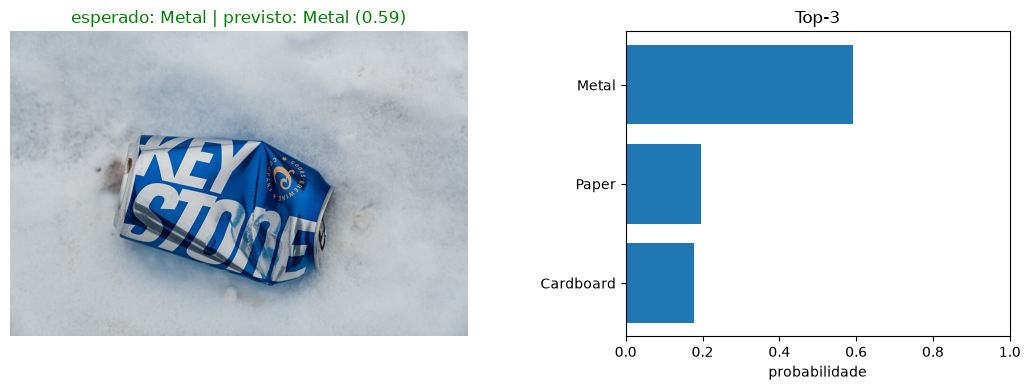

[('Metal', 0.5924023389816284),
 ('Paper', 0.19618815183639526),
 ('Cardboard', 0.1775328814983368)]

In [3]:
img, top3 = predict(IMAGE)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.5, 1]})
ax1.imshow(img); ax1.axis("off")
ax1.set_title(f"esperado: Metal | previsto: {top3[0][0]} ({top3[0][1]:.2f})",
              color="green" if top3[0][0] == "Metal" else "red")
ax2.barh([c for c, _ in top3][::-1], [s for _, s in top3][::-1], color="tab:blue")
ax2.set_xlim(0, 1); ax2.set_xlabel("probabilidade"); ax2.set_title("Top-3")
plt.tight_layout()
plt.show()
top3

**Comentário:**
- **O modelo acertou a classe Metal,** mas com confiança moderada (0,59). As alternativas foram Paper (0,20) e Cardboard (0,18).
- **Por que a confiança é moderada:** a imagem difere do RealWaste em dois aspectos.
  1. **Fundo de neve**, e não o piso de concreto da esteira (*domain shift*).
  2. **Rótulo impresso grande ocupando quase toda a lata.** Superfícies impressas são típicas de Paper e Cardboard no dataset, e o Grad-CAM já tinha mostrado
     que o modelo dá peso a regiões impressas.
- **Na prática:** numa esteira real, uma previsão com score abaixo de um limiar (ex.: 0,7) poderia ser encaminhada para triagem manual, em vez de decidida automaticamente.
- Esta demonstração mostra a reutilização do modelo com uma imagem externa. Ela não substitui a avaliação no conjunto de teste.
